In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [92]:
df = pd.read_csv('well_18_ml_v1.csv')
df.head()

,wellName,DEPTH,CGR,CPERM,CPHI,DT,DTSM,Facies,GR,MSFL,NPHI,PEF,Perm_Buckles_UpAs,PHIE,RHOB,RT,SWE,ZONE_NAME,net_gross
0,A-18-00,852.857,4.91913,-9999.0,-9999.0000,74.5270,121.9698,1,33.3418,5.79568,0.079834,4.783249,0.931011,0.072167,2.74411,10.27150,0.737652,U.Asmari,gross
1,A-18-00,853.010,9.99433,-9999.0,-9999.0000,88.8155,141.6838,1,53.4034,2.36973,0.151655,4.399977,9.209792,0.146527,2.61065,2.98569,0.667624,U.Asmari,gross
2,A-18-00,853.162,20.56400,-9999.0,-9999.0000,99.0574,166.7016,5,72.0957,1.31614,0.231567,4.030700,1.601786,0.220162,2.47339,1.38781,0.643816,U.Asmari,gross
3,A-18-00,853.314,31.71550,-9999.0,-9999.0000,104.7870,182.5868,5,78.3783,1.20371,0.287493,3.732858,3.690761,0.276589,2.35818,1.22050,0.541710,U.Asmari,net
4,A-18-00,853.467,37.70880,-9999.0,0.4288,104.8980,185.0199,5,70.4172,1.42773,0.297283,3.520631,5.106259,0.301175,2.29512,1.55953,0.438343,U.Asmari,net


In [93]:
df.replace(-9999, np.nan, inplace=True)

In [94]:
df.head()

,wellName,DEPTH,CGR,CPERM,CPHI,DT,DTSM,Facies,GR,MSFL,NPHI,PEF,Perm_Buckles_UpAs,PHIE,RHOB,RT,SWE,ZONE_NAME,net_gross
0,A-18-00,852.857,4.91913,NaN,NaN,74.5270,121.9698,1.0,33.3418,5.79568,0.079834,4.783249,0.931011,0.072167,2.74411,10.27150,0.737652,U.Asmari,gross
1,A-18-00,853.010,9.99433,NaN,NaN,88.8155,141.6838,1.0,53.4034,2.36973,0.151655,4.399977,9.209792,0.146527,2.61065,2.98569,0.667624,U.Asmari,gross
2,A-18-00,853.162,20.56400,NaN,NaN,99.0574,166.7016,5.0,72.0957,1.31614,0.231567,4.030700,1.601786,0.220162,2.47339,1.38781,0.643816,U.Asmari,gross
3,A-18-00,853.314,31.71550,NaN,NaN,104.7870,182.5868,5.0,78.3783,1.20371,0.287493,3.732858,3.690761,0.276589,2.35818,1.22050,0.541710,U.Asmari,net
4,A-18-00,853.467,37.70880,NaN,0.4288,104.8980,185.0199,5.0,70.4172,1.42773,0.297283,3.520631,5.106259,0.301175,2.29512,1.55953,0.438343,U.Asmari,net


In [95]:
dfm= df[['NPHI', 'RHOB', 'DT', 'GR', 'PHIE', 'ZONE_NAME', 'net_gross', 'Facies']].dropna()

dfm.head()


,NPHI,RHOB,DT,GR,PHIE,ZONE_NAME,net_gross,Facies
0,0.079834,2.74411,74.5270,33.3418,0.072167,U.Asmari,gross,1.0
1,0.151655,2.61065,88.8155,53.4034,0.146527,U.Asmari,gross,1.0
2,0.231567,2.47339,99.0574,72.0957,0.220162,U.Asmari,gross,5.0
3,0.287493,2.35818,104.7870,78.3783,0.276589,U.Asmari,net,5.0
4,0.297283,2.29512,104.8980,70.4172,0.301175,U.Asmari,net,5.0


In [96]:
dfm.count()

NPHI         664
RHOB         664
DT           664
GR           664
PHIE         664
ZONE_NAME    664
net_gross    664
Facies       664
dtype: int64

<Axes: xlabel='DT', ylabel='PHIE'>

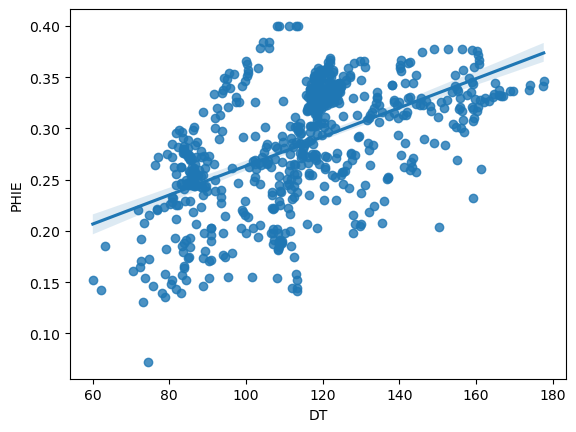

In [97]:
sns.regplot(x='DT', y='PHIE', data=dfm)

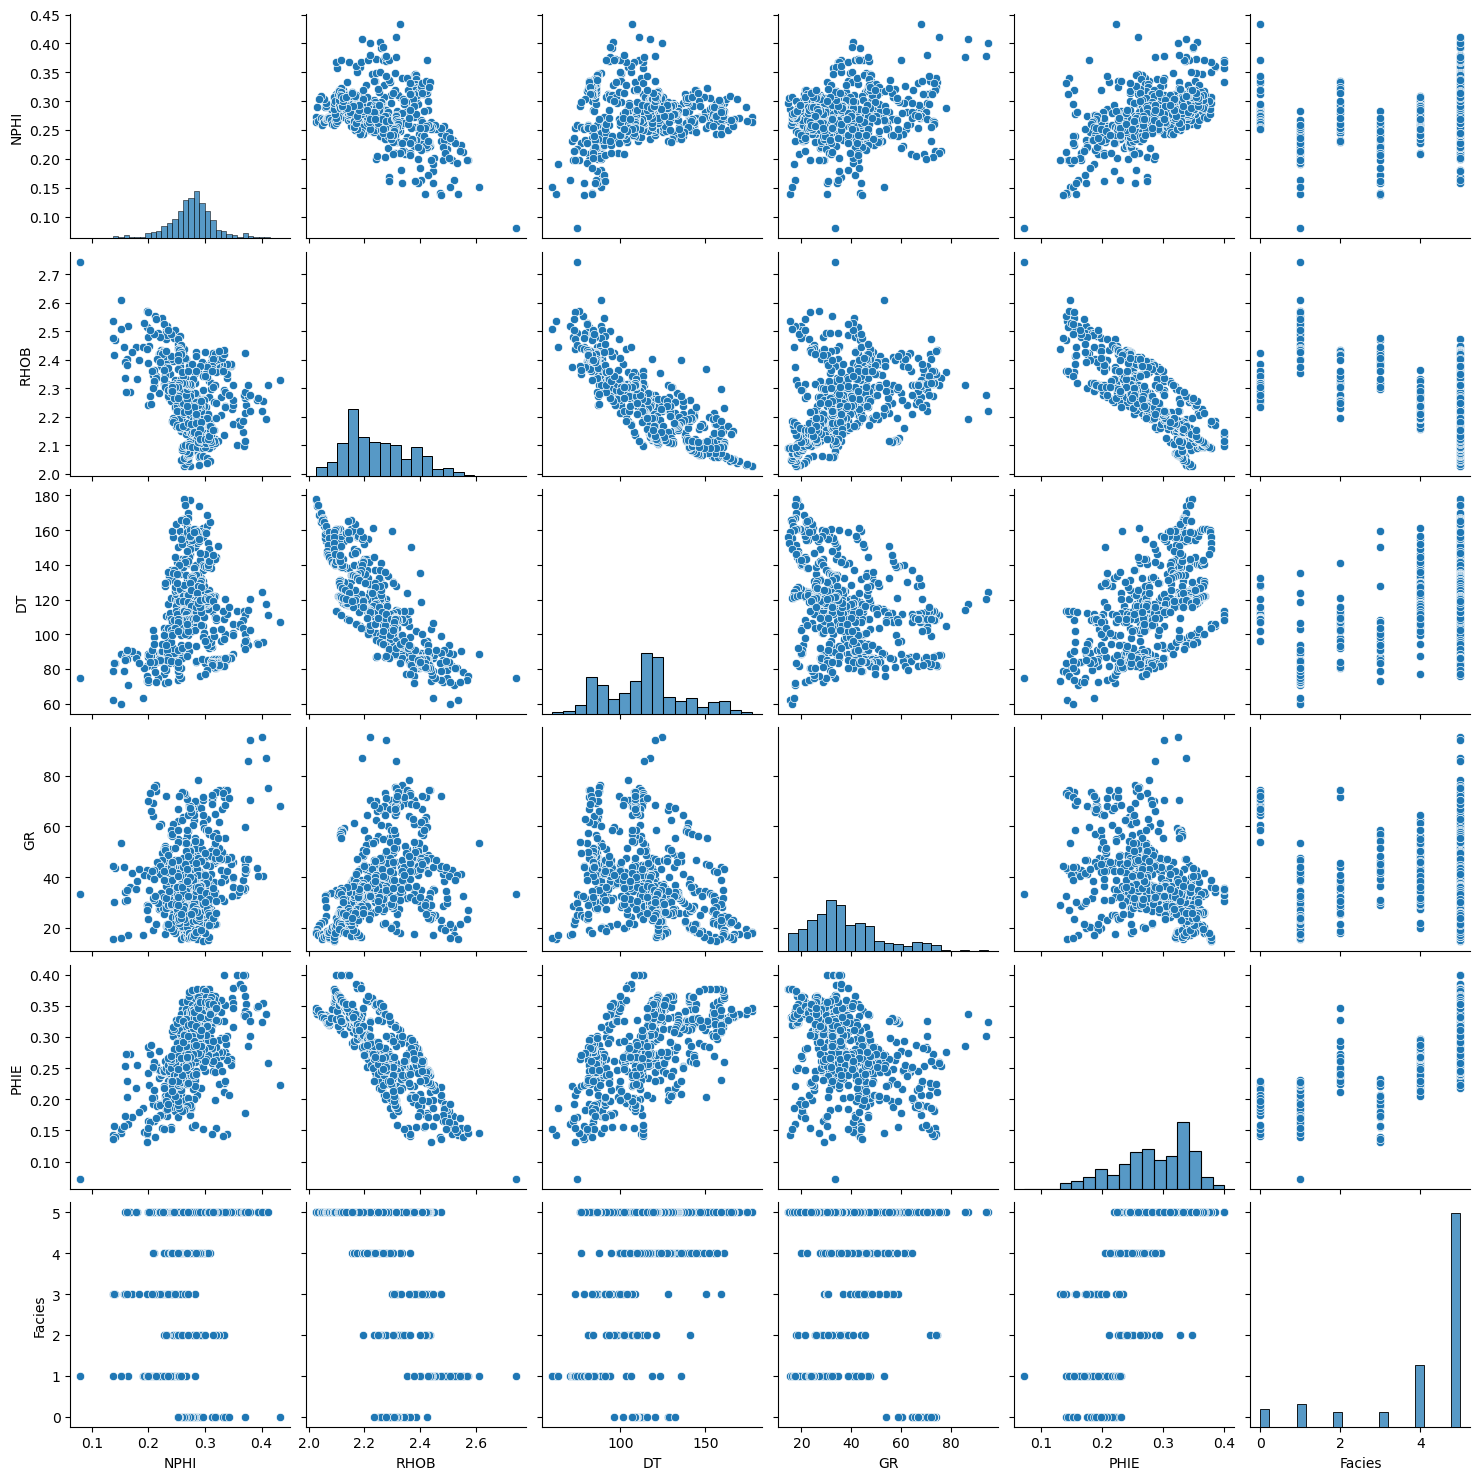

In [98]:
sns.pairplot(dfm)

In [99]:
dfm.corr(numeric_only=True)

,NPHI,RHOB,DT,GR,PHIE,Facies
NPHI,1.000000,-0.396963,0.195126,0.165611,0.557664,0.284477
RHOB,-0.396963,1.000000,-0.822232,0.381914,-0.840225,-0.564508
DT,0.195126,-0.822232,1.000000,-0.337350,0.547446,0.322223
GR,0.165611,0.381914,-0.337350,1.000000,-0.439440,-0.302250
PHIE,0.557664,-0.840225,0.547446,-0.439440,1.000000,0.773145
Facies,0.284477,-0.564508,0.322223,-0.302250,0.773145,1.000000


In [100]:
X= dfm.iloc[:, [0,1,2,3]]
y= dfm.iloc[:, -4]

In [101]:
y

0      0.072167
1      0.146527
2      0.220162
3      0.276589
4      0.301175
         ...   
730    0.327041
731    0.292937
732    0.261249
733    0.240001
734    0.226760
Name: PHIE, Length: 664, dtype: float64

In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

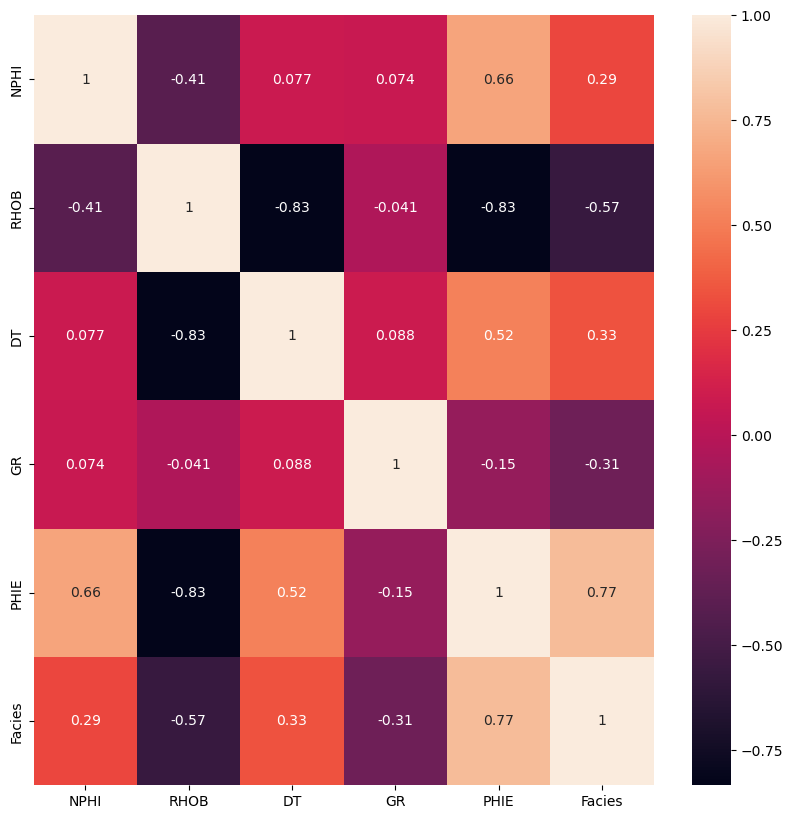

In [103]:
corrmat= dfm.corr(numeric_only=True)
top_corr= corrmat.index
plt.figure(figsize=(10,10))
g= sns.heatmap(df[top_corr].corr(numeric_only=True),annot=True)

In [104]:
print(f'shape of X_train: {X_train.shape}')
print(f'shape of y_train: {y_train.shape}')
print(f'shape of X_test: {X_test.shape}')
print(f'shape of y_test: {y_test.shape}')

shape of X_train: (498, 4)
shape of y_train: (498,)
shape of X_test: (166, 4)
shape of y_test: (166,)


In [144]:
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error

def reg_metrics (test, pred):
    
    print(f'MAE: {mean_absolute_error(test, pred)}')
    print(f'MSE: {mean_squared_error(test, pred)}')
    print(f'RMSE: {np.sqrt(mean_squared_error(test, pred))}')
    print(f'R2: {metrics.r2_score(test, pred)}')

def reg_plot (test, pred):
    sns.regplot(x=test, y=pred, scatter_kws={'color':'black'}, line_kws={'color':'red'})
    plt.xlim(0,max(test ))
    plt.ylim(0,max(pred ))
    plt.show()
    
def scatter_plot_comparison (test, pred):
    sns.scatterplot(x=test.index, y=test.values, color='red', label='Test data')
    sns.scatterplot(x=test.index, y=pred, color='blue', label='Predicted data')
    plt.show()

def line_plot_comparison (test, pred):
    plt.plot(test.values, color='red', label='Test data')
    plt.plot(pred, color='blue', label='Predicted data')
    plt.show()

Linear Regression model score: 1.294251479372564
Linear Regression model score: [ 0.42864713 -0.44106405 -0.0008256  -0.00113187]
MAE: 0.015833156098918066
MSE: 0.0004568189291009513
RMSE: 0.02137332283714798
R2: 0.8504489820105385


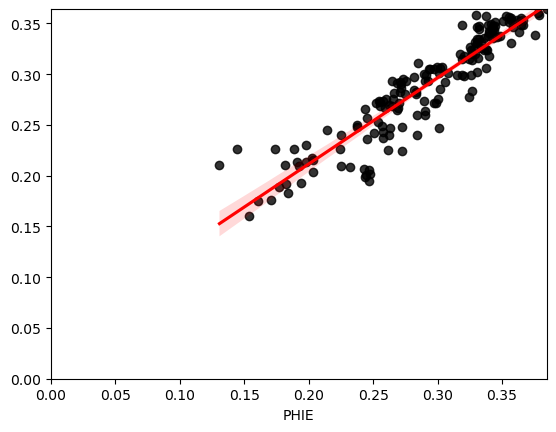

In [145]:
from sklearn.linear_model import LinearRegression
lin_reg= LinearRegression()
lin_reg.fit(X_train, y_train)
print(f'Linear Regression model score: {lin_reg.intercept_}')
print(f'Linear Regression model score: {lin_reg.coef_}')
y_pred_lin= lin_reg.predict(X_test)
reg_metrics(y_test, y_pred_lin)
reg_plot(y_test, y_pred_lin)

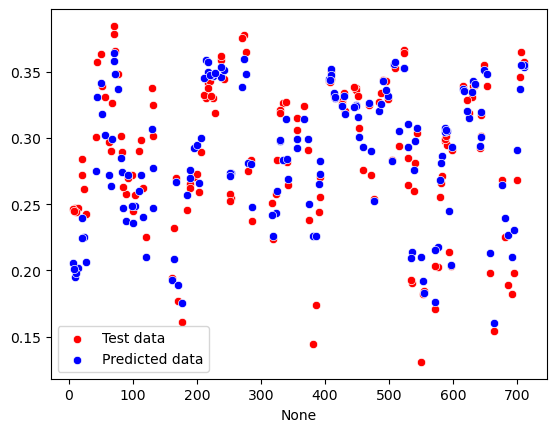

In [138]:
scatter_plot_comparison(y_test, y_pred_lin)